# E6 · Are the rules correct, and do guardrails matter? (live session)

PLAN §9, E6. Baseline: no guardrails. Stream C owns it. This notebook has four parts:

1. **Conflict check**: what the validator says about the shipped rule base.
2. **Scenario test cases**: hand-built members with the firings, allowed offers and blocked offers we expect
   (`tests/fixtures/rule_cases.yaml`, also run by `tests/test_rule_cases.py` as a regression test).
3. **Coverage on the 4,000 real members**: which rules fire, which never do, how often guardrails remove a playbook proposal.
4. **Plan value with vs without guardrails**: needs Stream B's optimiser; a marked stub at the end.

Everything is imported from `anchorai`; no rule logic is copied here. Nothing is written to the app DB or to Neo4j.
It reads the built data (`uv run anchorai data build`) and the cached KG facts (`uv run anchorai kg load`).

**Caveat (say it wherever these numbers are quoted).** The rule base is **hand-written by the team** and the thresholds
come from the training split of the real data (c_rules.ipynb). The scenario test cases test that the rules do what we
*meant*, not that what we meant is *right*; and because we wrote both, they are optimistic. `trend_ratio` and
`avg_class_frequency_current_month` are suspect features (`results/a_leakage.md`), so rules built on them (D01, D03, P01)
select members partly on information that may come from the churn month. `lost_anchor_instructor`, `class_cancelled`
and `days_since_last_contact` come from the **synthetic scenario layer**, so how often they fire reflects our simulator,
not real gyms.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from anchorai.reasoning.engine import load_rule_files, run
from anchorai.reasoning.facts import KNOWN_FACTS
from anchorai.reasoning.service import all_facts
from anchorai.reasoning.validate import validate
from anchorai.scenario.offers import OFFER_CATALOG
from anchorai.schemas import Channel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

rules = load_rule_files()
by_id = {r.id: r for r in rules}
offers = [o["offer_id"] for o in OFFER_CATALOG]
print(len(rules), "rules:", pd.Series([r.kind for r in rules]).value_counts().to_dict())

19 rules: {'playbook': 8, 'derive': 7, 'guardrail': 4}


## 1. Conflict check

`validate` flags duplicate ids, unknown facts/offers/channels, unreachable conditions and derive rules that contradict
each other. Expect an empty table for the shipped rule base. A non-empty one is a finding.

In [2]:
issues = validate(rules, KNOWN_FACTS, offers, [c.value for c in Channel])
issues_table = pd.DataFrame([i.model_dump() for i in issues], columns=["rule_id", "severity", "message"])
issues_table.to_csv(RES / "e6_validation_issues.csv", index=False)
print(len(issues), "issues")
issues_table

0 issues


,rule_id,severity,message


## 2. Scenario test cases

Each case is a fact set built by hand (base member + overrides), with the rules we expect to fire, the rules we expect
to stay silent, the offers allowed (in order) and the offers blocked. **Look for:** any row with `ok = False`. Decide
whether the rule or the expectation is wrong; the case file is `tests/fixtures/rule_cases.yaml`.

In [3]:
spec = yaml.safe_load(Path("../backend/tests/fixtures/rule_cases.yaml").read_text())


def case_facts(case):
    base = {k: v for k, v in spec["base"].items() if k not in spec.get("base_drop", [])}
    facts = {**base, **case.get("facts", {})}
    for key in case.get("drop", []):
        facts.pop(key, None)
    return facts


rows = []
for case in spec["cases"]:
    out = run(rules, case_facts(case), case["id"])
    fired = [f.rule_id for f in out.firings]
    want = case["expect"]
    checks = {
        "fires": set(want.get("fires", [])) <= set(fired),
        "silent": not set(want.get("silent", [])) & set(fired),
        "allowed": [p.offer_id for p in out.allowed] == want["allowed"],
        "blocked": out.blocked == want["blocked"] if "blocked" in want else True,
    }
    rows.append({
        "case": case["id"],
        "ok": all(checks.values()),
        "failed": ", ".join(k for k, v in checks.items() if not v),
        "fired": " ".join(r.split("_")[0] for r in fired),
        "allowed": ", ".join(p.offer_id for p in out.allowed),
        "blocked": ", ".join(f"{k}<-{v.split('_')[0]}" for k, v in out.blocked.items()),
        "title": case["title"],
    })
cases_table = pd.DataFrame(rows)
cases_table.to_csv(RES / "e6_scenario_cases.csv", index=False)
print(f"{cases_table['ok'].sum()} / {len(cases_table)} cases match")
cases_table

22 / 22 cases match


,case,ok,failed,fired,allowed,blocked,title
0,steady_low_risk,True,,G03 G04,,"discount_1m<-G03, free_pt_session<-G04, class_...","Steady, low-risk member needs nothing"
1,new_and_slipping_medium,True,,D02 P01 P08,"free_pt_session, checkin_message",,"New member whose visits are falling, medium ri..."
2,high_value_at_risk,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,High-value member at high risk gets a PT sessi...
3,month_to_month_high_risk,True,,P05,discount_1m,,"Month-to-month member at high risk, below the ..."
4,discount_never_proposed_off_month_to_month,True,,G03,,discount_1m<-G03,High risk on a 6-month contract below the high...
5,recently_contacted,True,,G01 G03 D05 P06,,"all<-G01, discount_1m<-G03",A playbook proposes but the contact-fatigue gu...
6,contact_30_days_ago,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,Exactly 30 days since the last contact is allo...
7,offer_cap_reached,True,,G02 G03 D05 P06,,"all<-G02, discount_1m<-G03",Two offers in 90 days blocks everything even w...
8,never_contacted,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,"A never-contacted member has no contact facts,..."
9,lost_anchor_instructor,True,,G03 G04 D07 P03,checkin_message,"discount_1m<-G03, free_pt_session<-G04, class_...",Low-risk member whose instructor left still ge...


Cases that are **not** testable with the shipped fact vocabulary (findings, not failures):

- **Opted-out members.** There is no opt-out / consent fact in `KNOWN_FACTS` and no guardrail for it, so "never contact a
  member who opted out" cannot be expressed or tested. Decided 2026-10-16: **out of scope**; the report
  states that consent / opt-out handling is assumed to happen in the gym's messaging tool, not in AnchorAI.
- **Instructor left, member never attended their classes.** Covered upstream by the KG signal, not by a rule.

## 3. Coverage on the real members

`all_facts()` builds facts for every member from Stream A's built tables and the cached KG facts, exactly as the API does.

In [4]:
facts = all_facts()
outcomes = {m: run(rules, f, m) for m, f in facts.items()}
n = len(outcomes)
print(n, "members")

fired = pd.Series([f.rule_id for o in outcomes.values() for f in o.firings]).value_counts()
coverage = pd.DataFrame({
    "kind": [r.kind for r in rules],
    "members": [int(fired.get(r.id, 0)) for r in rules],
}, index=[r.id for r in rules])
coverage["share"] = coverage["members"] / n
coverage["never_fires"] = coverage["members"] == 0
coverage.round(3).to_csv(RES / "e6_rule_coverage.csv")
print("rules that never fire:", coverage.index[coverage["never_fires"]].tolist())
coverage.round(3)

4000 members
rules that never fire: ['G02_offer_cap']


,kind,members,share,never_fires
D01_falling_regular,derive,127,0.032,False
D02_new_member,derive,1330,0.332,False
D03_disengaged,derive,502,0.126,False
D05_high_value_at_risk,derive,975,0.244,False
D06_social_member,derive,1234,0.308,False
D07_lost_instructor,derive,186,0.046,False
D08_class_cancelled,derive,173,0.043,False
G01_contact_fatigue,guardrail,475,0.119,False
G02_offer_cap,guardrail,0,0.000,True
G03_discount_eligibility,guardrail,1793,0.448,False


A rule that never fires is either redundant or a symptom of the scenario layer. Check the inputs of each such rule
below before deciding.

In [5]:
never = coverage.index[coverage["never_fires"]].tolist()
for rule_id in never:
    for c in by_id[rule_id].conditions:
        values = pd.Series([f[c.fact] for f in facts.values() if c.fact in f])
        print(rule_id, "|", c, "|", f"{len(values)}/{n} members have it;", values.describe().round(2).to_dict() if values.dtype != object else values.value_counts().to_dict())

G02_offer_cap | offers_last_90d >= 2 | 4000/4000 members have it; {'count': 4000.0, 'mean': 0.35, 'std': 0.48, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 1.0, 'max': 1.0}


### How often do guardrails remove a proposal?

For every member: what the playbooks proposed (`proposals`) versus what survived the guardrails (`allowed`).
`blocked_by` attributes each removed proposal to the guardrail that blocked it (the engine records the first guardrail
per target).

In [6]:
removed = []
for m, o in outcomes.items():
    for p in o.proposals:
        by = o.blocked.get("all") or o.blocked.get(p.offer_id)
        if by:
            removed.append({"member": m, "playbook": p.rule_id, "offer": p.offer_id, "blocked_by": by})
removed = pd.DataFrame(removed)

n_proposals = sum(len(o.proposals) for o in outcomes.values())
print(f"{n_proposals} proposals over {sum(bool(o.proposals) for o in outcomes.values())} members; "
      f"{len(removed)} proposals removed by guardrails ({len(removed) / n_proposals:.1%})")
by_guard = (removed.groupby("blocked_by").agg(proposals_removed=("member", "size"), members=("member", "nunique"))
            .reindex([r.id for r in rules if r.kind == "guardrail"]).fillna(0).astype(int))
by_guard["members_matching_guardrail"] = coverage.loc[by_guard.index, "members"]
by_guard.to_csv(RES / "e6_guardrail_bites.csv")
by_guard

3486 proposals over 1406 members; 495 proposals removed by guardrails (14.2%)


,proposals_removed,members,members_matching_guardrail
blocked_by,,,
G01_contact_fatigue,484,197,475
G02_offer_cap,0,0,0
G03_discount_eligibility,0,0,1793
G04_low_risk_no_paid_offers,11,11,2886


In [7]:
pd.crosstab(removed["playbook"], removed["blocked_by"], margins=True) if len(removed) else "nothing removed"

blocked_by,G01_contact_fatigue,G04_low_risk_no_paid_offers,All
playbook,,,
P01_new_member_onboarding,69,10,79
P02_falling_regular_pt,17,1,18
P03_disrupted_checkin,51,0,51
P04_social_class_pass,24,0,24
P05_month_to_month_discount,128,0,128
P06_high_value_pt,138,0,138
P07_disengaged_checkin,39,0,39
P08_medium_risk_checkin,18,0,18
All,484,11,495


### Where do members end up?

Each member falls in exactly one bucket: has an allowed offer; had proposals but guardrails removed all of them; or no
playbook proposed anything. **Look for:** how many high-risk members have no allowed offer, and why.

In [8]:
def bucket(o):
    if o.allowed:
        return "has allowed offer"
    if o.proposals:
        return "blocked: all" if "all" in o.blocked else "blocked: offer-level"
    return "no playbook matched"


outcome_table = pd.DataFrame({
    "bucket": pd.Series({m: bucket(o) for m, o in outcomes.items()}),
    "risk_band": pd.Series({m: o.facts["risk_band"] for m, o in outcomes.items()}),
})
by_band = pd.crosstab(outcome_table["risk_band"], outcome_table["bucket"], margins=True).reindex(["high", "medium", "low", "All"])
by_band.to_csv(RES / "e6_member_outcomes.csv")
by_band

bucket,blocked: all,blocked: offer-level,has allowed offer,no playbook matched,All
risk_band,,,,,
high,140,0,846,4,990
medium,18,0,106,0,124
low,39,8,249,2590,2886
All,197,8,1201,2594,4000


In [9]:
nothing = outcome_table["bucket"] != "has allowed offer"
print(f"members with no allowed offer: {nothing.sum()} ({nothing.mean():.1%}); "
      f"of high-risk members: {(nothing & (outcome_table['risk_band'] == 'high')).sum()} / {(outcome_table['risk_band'] == 'high').sum()}")
print("offers_last_90d:", pd.Series([f.get("offers_last_90d", 0) for f in facts.values()]).value_counts().sort_index().to_dict())
print("days_since_last_contact < 30:", sum(f.get("days_since_last_contact", 999) < 30 for f in facts.values()), "| never contacted:", sum("days_since_last_contact" not in f for f in facts.values()))

members with no allowed offer: 2799 (70.0%); of high-risk members: 144 / 990
offers_last_90d: {0: 2584, 1: 1416}
days_since_last_contact < 30: 475 | never contacted: 2584


### Without guardrails

The same playbooks with the guardrails switched off (still the real engine and real rules; `enabled=False` is a field on
the rule). This is the *count* version of the baseline: how many contacts a guardrail-free system would make that the
guardrails forbid. The *value* version is part 4.

In [10]:
no_guard = [r.model_copy(update={"enabled": False}) if r.kind == "guardrail" else r for r in rules]
free = {m: run(no_guard, f, m) for m, f in facts.items()}
rule_kinds = {r.id: r for r in rules}

rows = []
for m, o in outcomes.items():
    for p in free[m].allowed:
        kept = any(a.offer_id == p.offer_id for a in o.allowed)
        rows.append({"member": m, "offer": p.offer_id, "kept": kept,
                     "violates": "" if kept else (o.blocked.get("all") or o.blocked.get(p.offer_id))})
free_offers = pd.DataFrame(rows)
summary = pd.DataFrame({
    "members_with_offer": [sum(bool(o.allowed) for o in free.values()), sum(bool(o.allowed) for o in outcomes.values())],
    "offers_total": [len(free_offers), int(free_offers["kept"].sum())],
}, index=["no guardrails", "with guardrails"])
summary["share_of_offers_removed"] = [0.0, 1 - free_offers["kept"].mean()]
summary.round(3).to_csv(RES / "e6_with_vs_without_guardrails.csv")
print(free_offers.loc[~free_offers["kept"], "violates"].value_counts().to_dict())
summary.round(3)

{'G01_contact_fatigue': 396, 'G04_low_risk_no_paid_offers': 11}


,members_with_offer,offers_total,share_of_offers_removed
no guardrails,1406,2832,0.000
with guardrails,1201,2425,0.144


In [11]:
fired_free_offers = free_offers[~free_offers["kept"]]
pd.crosstab(fired_free_offers["offer"], fired_free_offers["violates"], margins=True)

violates,G01_contact_fatigue,G04_low_risk_no_paid_offers,All
offer,,,
checkin_message,103,0,103
class_pass,24,0,24
discount_1m,128,0,128
free_pt_session,141,11,152
All,396,11,407


### Figure

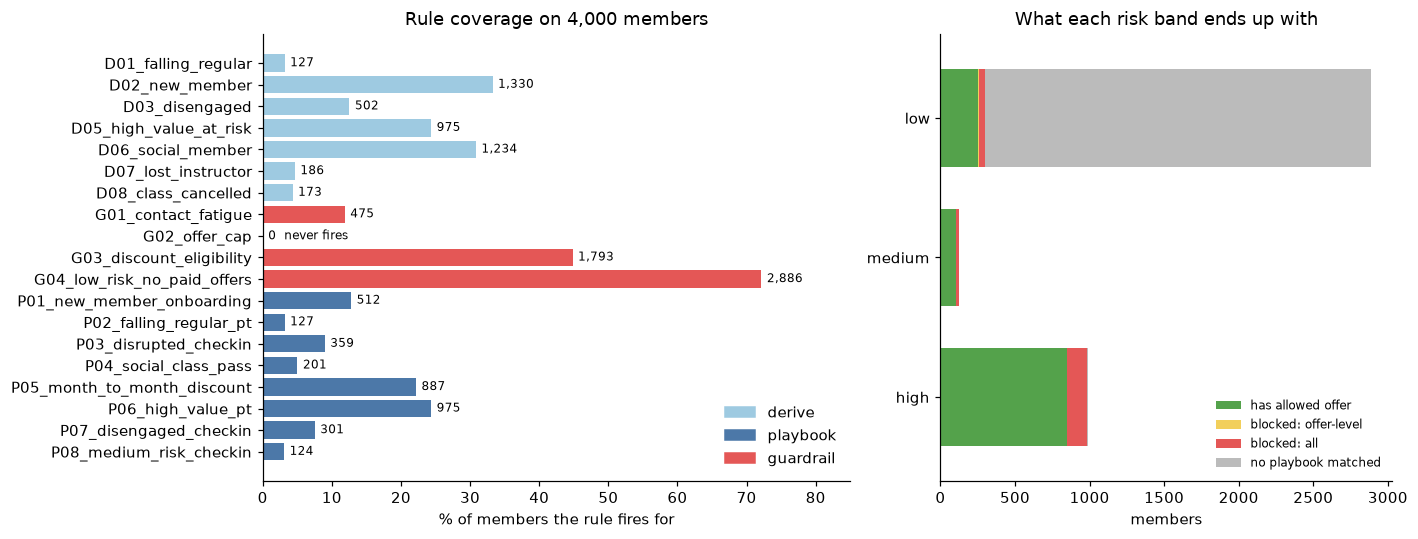

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
colour = {"derive": "#9ecae1", "playbook": "#4c78a8", "guardrail": "#e45756"}
cov = coverage.iloc[::-1]
a.barh(cov.index, cov["share"] * 100, color=[colour[k] for k in cov["kind"]])
for y, (share, m) in enumerate(zip(cov["share"], cov["members"])):
    a.text(share * 100 + 0.8, y, f"{m:,}" if m else "0  never fires", va="center", fontsize=8)
a.set_xlabel("% of members the rule fires for")
a.set_xlim(0, 85)
a.set_title("Rule coverage on 4,000 members")
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colour.values()], labels=colour.keys(), loc="lower right", frameon=False)

order = ["has allowed offer", "blocked: offer-level", "blocked: all", "no playbook matched"]
shade = {"has allowed offer": "#54a24b", "blocked: offer-level": "#f2cf5b", "blocked: all": "#e45756", "no playbook matched": "#bbbbbb"}
t = by_band.drop(columns="All", index="All").reindex(columns=order, fill_value=0)
t.plot.barh(stacked=True, ax=b, color=[shade[c] for c in t.columns], width=0.7)
b.set_xlabel("members")
b.set_ylabel("")
b.set_title("What each risk band ends up with")
b.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e6_rule_coverage.png", bbox_inches="tight")

## 4. Plan value with vs without guardrails  (pending Stream B)

**Not runnable yet.** The question is how much expected retention (scenario ground truth, E4's metric) the optimiser's
plan gains or loses when the guardrails are removed from the candidate set, at several budget levels and 5 seeds. It needs
Stream B's optimiser and policy evaluator (`anchorai.optimisation`) and the candidate-set interface that takes
`RuleOutcome.allowed`. HANDOFFS tracks it. When it lands:

1. Candidates with guardrails = `RuleOutcome.allowed` from the rule run above. Candidates without = `free[m].allowed`
   (the guardrail-free run above), same members, same budgets.
2. Score both plans with B's evaluator on `true_uplift`; report retained members per budget and the *constraint
   violations* of the guardrail-free plan (contacts inside 30 days, over-cap members), since those are what the guardrails
   exist to prevent and what makes the unconstrained plan unacceptable even if it scores higher.
3. Expect the guardrail-free plan to look no worse on retention (it has a superset of candidates). The result worth
   reporting is how much value the guardrails cost and what they prevent, not that they "help".

In [13]:
# Pending Stream B: replace with the optimiser call. Nothing to run yet.
print("Part 4 is waiting for anchorai.optimisation (Stream B).")

Part 4 is waiting for anchorai.optimisation (Stream B).


## 5. Findings

From the run on 2026-10-16. Part 4 (plan value) is still waiting for Stream B.

1. **Validator and cases.** 0 validator issues; 22 of 22 scenario cases match the shipped rules.
2. **`G02_offer_cap` never fires** on the 4,000 members: `offers_last_90d` is 0 or 1 for everyone in the scenario layer, so
   the cap of 2 is unreachable. It is data, not a bug: the simulator never contacts a member twice in 90 days. State it
   in the report; it also means G02 is untested on real data (the scenario cases do exercise it).
3. **`G03_discount_eligibility` never removes a proposal.** Its only proposer, P05, already requires
   `contract_period == 1`, so G03 matches 1,793 members but blocks nothing the playbooks propose. It is a safety net for
   manual plan overrides (HANDOFFS #12) and future playbooks, not a working guardrail today.
4. **What guardrails actually do:** of 3,486 proposals, 495 (14.2%) are removed: 484 by `G01_contact_fatigue`
   (197 members) and 11 by `G04_low_risk_no_paid_offers`. 144 of 990 high-risk members end with no allowed offer, 140
   because of contact fatigue.
5. **70% of members have no allowed offer**, but 2,590 of those are low-risk members that no playbook targets (by design).
   Only 4 high-risk members have no playbook at all.
6. **Medium risk is a thin band** (124 members, 3.1%), so P04, P07 and P08 mostly act on high-risk members.
7. **No opt-out fact** exists, so "never contact opted-out members" cannot be expressed (see part 2). Decided: out
   of scope, stated in the report.
8. **Low-risk new-and-slipping members** (P01, P02) are proposed a PT session and then blocked by G04 (11 cases). Decided:
   **keep G04 as is.** The churn model already weighs tenure heavily (months as a member is a top driver), so a new
   member it still scores low risk is not worth a paid session. G04 blocks only paid offers, so free contacts are
   unaffected, and the blocked proposals stay visible in the trace so staff can see the choice.
9. **With vs without guardrails (counts):** switching the guardrails off gives 1,406 members an offer instead of 1,201,
   and 2,832 offers instead of 2,425. The 407 extra offers (14.4%) are 396 contacts inside 30 days of the last one (G01)
   and 11 paid offers to low-risk members (G04). Whether removing them costs retention is part 4.
